# 🚗 Projet Data Mining — Prédiction des Sinistres Automobile
### Dataset : `Insurance_claims_data.csv` — 58 592 polices · 41 variables · Cible : `claim_status`

---
| Étape | Contenu |
|---|---|
| **1. EDA** | Type de problème, déséquilibre, variables quanti/quali, tests statistiques |
| **2. Preprocessing** | Nettoyage, encodage, feature engineering, split, scaling |
| **3. Équilibrage** | SMOTE, SMOTE-NC, sous/sur-échantillonnage |
| **4. Sélection** | Filtre SelectKBest + Wrapper RFECV + Intersection |
| **5. Modélisation** | AFD, Logit, Arbre, Random Forest + XGBoost (PyCaret) |
| **6. Évaluation** | ROC, PR, confusion, Youden J, Bootstrap IC95% |
| **7. Interprétabilité** | SHAP summary, beeswarm, waterfall, dependence plots |
| **8. Synthèse** | Recommandations métier |


## 0. Vérification des dépendances & Configuration

In [58]:
# ── Installation des packages si nécessaires ─────────────────────────────────
import subprocess, sys

packages = ['imbalanced-learn', 'xgboost', 'lightgbm', 'shap', 'pycaret']
for pkg in packages:
    try:
        __import__(pkg.replace('-','_').split('[')[0])
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print("✅ Toutes les dépendances sont disponibles")


✅ Toutes les dépendances sont disponibles


In [59]:
# ── Imports standard ──────────────────────────────────────────────────────────
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from   matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from   scipy  import stats
import warnings
warnings.filterwarnings('ignore')

# ── Sklearn ───────────────────────────────────────────────────────────────────
from sklearn.model_selection      import train_test_split, StratifiedKFold,                                          GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing        import StandardScaler, LabelEncoder
from sklearn.feature_selection    import SelectKBest, f_classif, RFECV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model         import LogisticRegression
from sklearn.tree                 import DecisionTreeClassifier, export_text
from sklearn.ensemble             import RandomForestClassifier
from sklearn.svm                  import SVC
from sklearn.neighbors            import KNeighborsClassifier
from sklearn.metrics              import (roc_auc_score, roc_curve,
                                          precision_recall_curve,
                                          average_precision_score,
                                          classification_report,
                                          confusion_matrix,
                                          ConfusionMatrixDisplay, f1_score)
from sklearn.inspection           import permutation_importance

# ── Imbalanced-learn ──────────────────────────────────────────────────────────
from imblearn.over_sampling       import SMOTE, SMOTENC, RandomOverSampler
from imblearn.under_sampling      import RandomUnderSampler
from imblearn.combine             import SMOTETomek
from imblearn.pipeline            import Pipeline as ImbPipeline

# ── Boosting ──────────────────────────────────────────────────────────────────
from xgboost  import XGBClassifier
from lightgbm import LGBMClassifier

# ── SHAP ──────────────────────────────────────────────────────────────────────
import shap
shap.initjs()

# ══════════════════════════════════════════════════════════════════════════════
# PALETTE CORPORATE — même thème sur tous les graphiques
# ══════════════════════════════════════════════════════════════════════════════
MY_PALETTE = ["#2C3E50", "#E74C3C", "#BDC3C7", "#3498DB"]
DARK, RED, GRAY, BLUE = "#2C3E50", "#E74C3C", "#BDC3C7", "#3498DB"
WHITE = "#FFFFFF"
CMAP_CORP = LinearSegmentedColormap.from_list('corp', [BLUE, WHITE, RED], N=256)

sns.set_theme(style="whitegrid")
sns.set_palette(MY_PALETTE)
plt.rcParams.update({
    'font.family'      : 'DejaVu Sans',
    'axes.titlesize'   : 13, 'axes.titleweight': 'bold', 'axes.titlecolor': DARK,
    'axes.labelcolor'  : DARK, 'axes.edgecolor': GRAY,
    'xtick.color'      : DARK, 'ytick.color': DARK,
    'grid.color'       : '#E8EAF0', 'grid.linewidth': 0.6,
    'figure.facecolor' : WHITE,  'axes.facecolor': WHITE,
})
print("✅ Configuration OK — Palette :", MY_PALETTE)


✅ Configuration OK — Palette : ['#2C3E50', '#E74C3C', '#BDC3C7', '#3498DB']


---
## Étape 1 — Analyse Exploratoire (EDA)
### 1.1 Chargement & Type de problème

In [60]:
# ── Chargement ────────────────────────────────────────────────────────────────
df = pd.read_csv('Insurance_claims.csv')

print("=" * 65)
print(f"  Observations  : {df.shape[0]:,}")
print(f"  Variables     : {df.shape[1]}")
print(f"  Mémoire       : {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print("=" * 65)

# ── Classification des variables ──────────────────────────────────────────────
id_col    = ['policy_id']
target    = 'claim_status'

# Quantitatives continues
quanti_cols = ['subscription_length','vehicle_age','region_density',
               'turning_radius','length','width','gross_weight',
               'displacement']
# Quantitatives discrètes
quanti_disc = ['customer_age','airbags','cylinder','ncap_rating']

# Qualitatives binaires Yes/No
quali_bin   = [c for c in df.columns
               if df[c].dtype == object
               and set(df[c].dropna().unique()) <= {'Yes','No'}]

# Qualitatives multi-modales
quali_multi  = ['region_code','segment','model','fuel_type',
                'engine_type','rear_brakes_type','transmission_type',
                'steering_type']

# Mixtes (texte avec valeur numérique)
mixed_cols   = ['max_torque','max_power']

print(f"\n  TYPE DE PROBLÈME : Classification binaire supervisée")
print(f"  Variable cible   : claim_status (0=Non-sinistre, 1=Sinistre)")
print(f"\n  Variables quantitatives continues  : {len(quanti_cols)} → {quanti_cols}")
print(f"  Variables quantitatives discrètes  : {len(quanti_disc)} → {quanti_disc}")
print(f"  Variables qualitatives binaires    : {len(quali_bin)}  (Yes/No)")
print(f"  Variables qualitatives multi-mod.  : {len(quali_multi)} → {quali_multi}")
print(f"  Variables texte mixte              : {mixed_cols}")
print(f"\n  Valeurs manquantes                 : {df.isnull().sum().sum()}")
print(f"  Doublons                           : {df.duplicated().sum()}")


  Observations  : 58,592
  Variables     : 41
  Mémoire       : 26.5 MB

  TYPE DE PROBLÈME : Classification binaire supervisée
  Variable cible   : claim_status (0=Non-sinistre, 1=Sinistre)

  Variables quantitatives continues  : 8 → ['subscription_length', 'vehicle_age', 'region_density', 'turning_radius', 'length', 'width', 'gross_weight', 'displacement']
  Variables quantitatives discrètes  : 4 → ['customer_age', 'airbags', 'cylinder', 'ncap_rating']
  Variables qualitatives binaires    : 0  (Yes/No)
  Variables qualitatives multi-mod.  : 8 → ['region_code', 'segment', 'model', 'fuel_type', 'engine_type', 'rear_brakes_type', 'transmission_type', 'steering_type']
  Variables texte mixte              : ['max_torque', 'max_power']

  Valeurs manquantes                 : 0
  Doublons                           : 0


### 1.2 Déséquilibre de la variable cible — Test Binomial

  Classe 0 (Non-sinistre) : 54,844 (93.60%)
  Classe 1 (Sinistre)     : 3,748 (6.40%)
  Ratio déséquilibre      : 1 sinistre / 14 non-sinistres
  Test binomial p-value   : 0.00e+00  → rejet de H0
  ⚠️  Déséquilibre statistiquement certain → traitement obligatoire


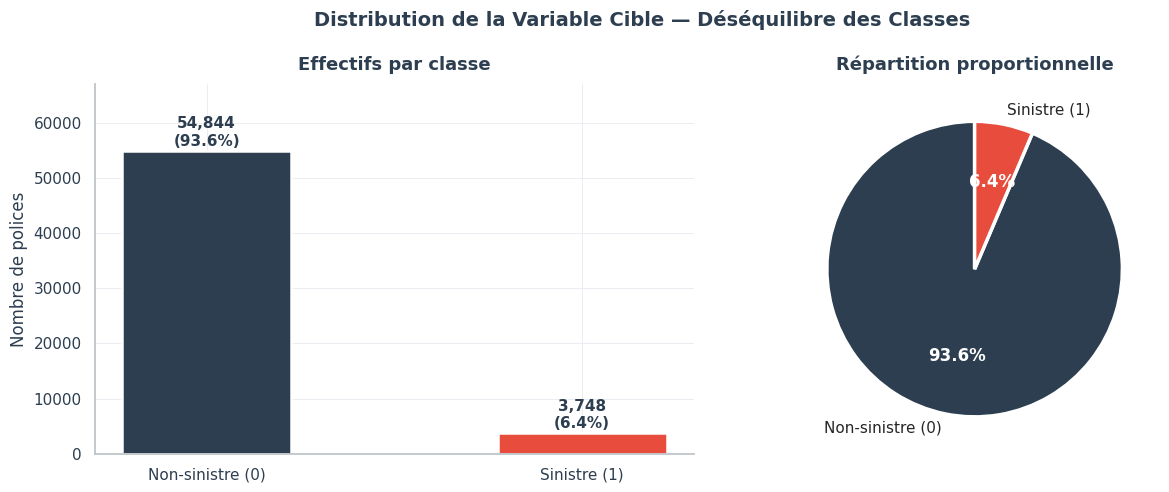

In [61]:
from scipy.stats import binomtest

counts = df['claim_status'].value_counts().sort_index()
total  = len(df)
p_obs  = counts[1] / total

# Test binomial H0 : P(sinistre) = 0.5
binom_result = binomtest(counts[1], total, p=0.5, alternative='two-sided')

print("=" * 55)
print(f"  Classe 0 (Non-sinistre) : {counts[0]:,} ({counts[0]/total*100:.2f}%)")
print(f"  Classe 1 (Sinistre)     : {counts[1]:,} ({counts[1]/total*100:.2f}%)")
print(f"  Ratio déséquilibre      : 1 sinistre / {int(counts[0]/counts[1])} non-sinistres")
print(f"  Test binomial p-value   : {binom_result.pvalue:.2e}  → rejet de H0")
print(f"  ⚠️  Déséquilibre statistiquement certain → traitement obligatoire")
print("=" * 55)

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Distribution de la Variable Cible — Déséquilibre des Classes",
             fontsize=14, fontweight='bold', color=DARK)

# Barplot
ax = axes[0]
bars = ax.bar(['Non-sinistre (0)', 'Sinistre (1)'],
              counts.values, color=[DARK, RED],
              width=0.45, edgecolor='white', linewidth=1.8)
ax.set_title("Effectifs par classe", pad=10)
ax.set_ylabel("Nombre de polices")
ax.set_ylim(0, counts.max() * 1.22)
for bar, cnt in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+400,
            f'{cnt:,}\n({cnt/total*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', color=DARK, fontsize=11)
ax.spines[['top','right']].set_visible(False)

# Pie
ax2 = axes[1]
wedges, texts, ats = ax2.pie(
    counts.values, labels=['Non-sinistre (0)', 'Sinistre (1)'],
    colors=[DARK, RED], autopct='%1.1f%%', startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2.5})
for at in ats:
    at.set(color='white', fontweight='bold', fontsize=12)
ax2.set_title("Répartition proportionnelle", pad=10)

plt.tight_layout()
plt.show()


### 1.3 Statistiques descriptives — Variables quantitatives

In [62]:
all_quanti = quanti_cols + quanti_disc
desc = df[all_quanti].describe().T
desc['skewness'] = df[all_quanti].skew()
desc['kurtosis'] = df[all_quanti].kurt()
print("Statistiques descriptives des variables quantitatives :")
print(desc[['mean','std','min','25%','50%','75%','max','skewness','kurtosis']].round(2).to_string())


Statistiques descriptives des variables quantitatives :
                         mean       std     min     25%     50%      75%      max  skewness  kurtosis
subscription_length      6.11      4.14     0.0     2.1     5.7     10.4     14.0      0.05     -1.50
vehicle_age              1.39      1.13     0.0     0.4     1.2      2.2     20.0      1.09      5.30
region_density       18826.86  17660.17   290.0  6112.0  8794.0  27003.0  73430.0      1.67      2.59
turning_radius           4.85      0.23     4.5     4.6     4.8      5.0      5.2      0.42     -1.18
length                3850.48    311.46  3445.0  3445.0  3845.0   3995.0   4300.0      0.15     -1.21
width                 1672.23    112.09  1475.0  1515.0  1735.0   1755.0   1811.0     -0.49     -1.44
gross_weight          1385.28    212.42  1051.0  1185.0  1335.0   1510.0   1720.0      0.55     -1.02
displacement          1162.36    266.30   796.0   796.0  1197.0   1493.0   1498.0     -0.11     -1.34
customer_age            44

### 1.4 Analyse des variables qualitatives

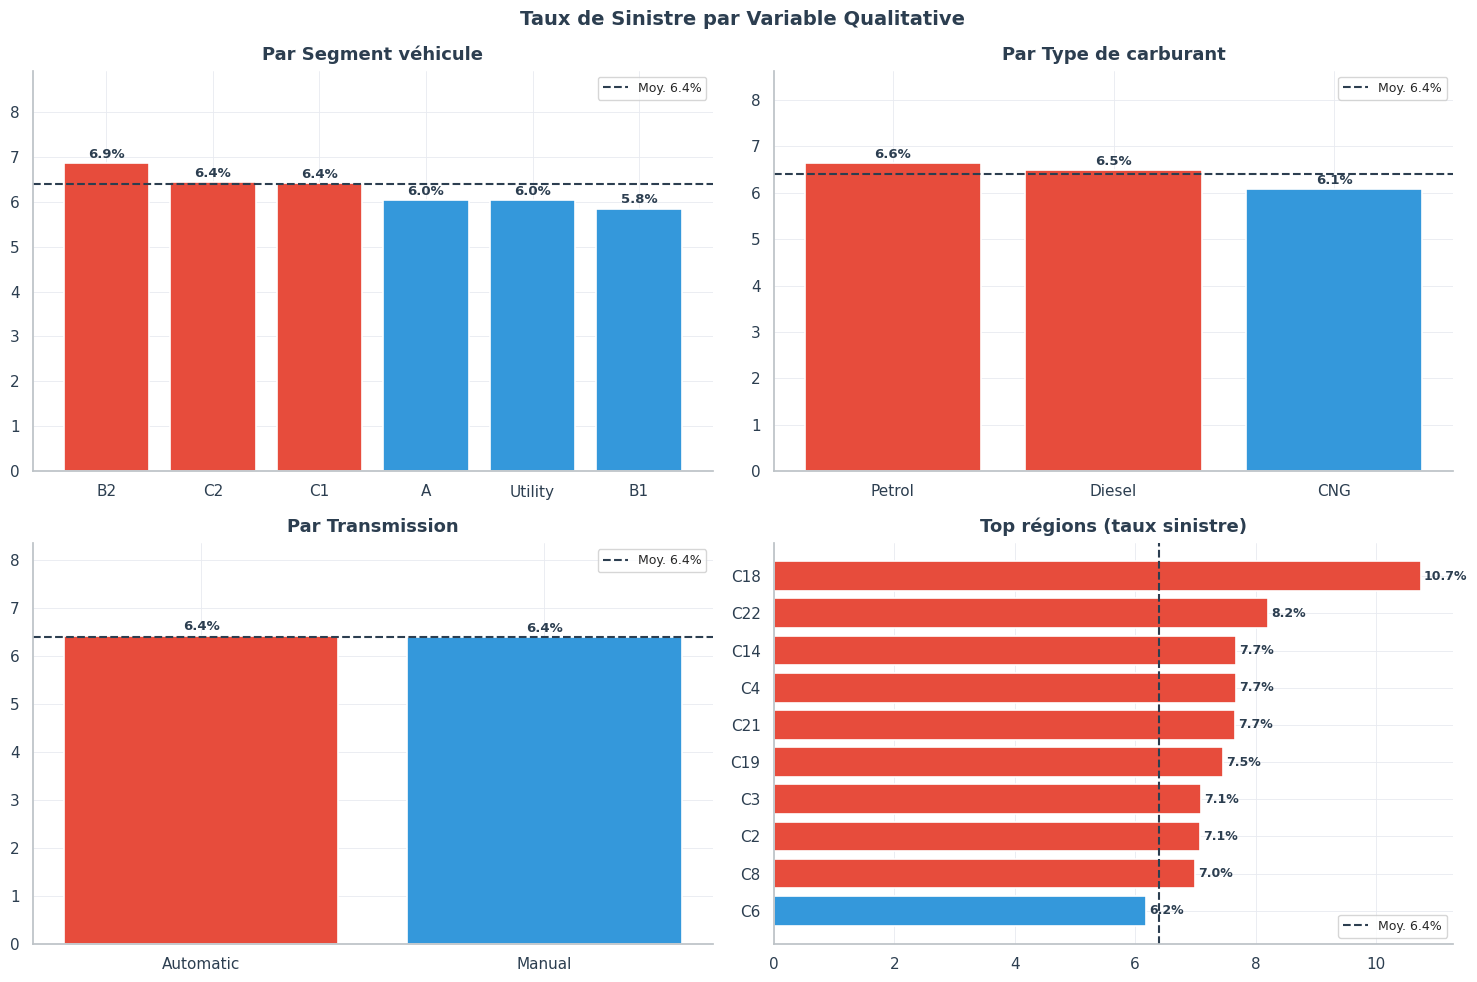

In [63]:
mean_global = df['claim_status'].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Taux de Sinistre par Variable Qualitative",
             fontsize=14, fontweight='bold', color=DARK)

def barplot_claim_rate(ax, col, title, horizontal=False, top_n=None):
    taux = df.groupby(col)['claim_status'].mean().sort_values(ascending=False) * 100
    if top_n:
        taux = taux.head(top_n)
    colors = [RED if v > mean_global else BLUE for v in taux.values]
    if horizontal:
        ax.barh(taux.index[::-1], taux.values[::-1], color=colors[::-1],
                edgecolor='white', linewidth=1.2)
        ax.axvline(mean_global, color=DARK, linestyle='--', lw=1.5,
                   label=f'Moy. {mean_global:.1f}%')
        for i, v in enumerate(taux.values[::-1]):
            ax.text(v+0.05, i, f'{v:.1f}%', va='center', fontsize=9,
                    fontweight='bold', color=DARK)
    else:
        bars = ax.bar(taux.index, taux.values, color=colors,
                      edgecolor='white', linewidth=1.2)
        ax.axhline(mean_global, color=DARK, linestyle='--', lw=1.5,
                   label=f'Moy. {mean_global:.1f}%')
        ax.set_ylim(0, taux.max() * 1.3)
        for bar, v in zip(bars, taux.values):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
                    f'{v:.1f}%', ha='center', va='bottom', fontsize=9.5,
                    fontweight='bold', color=DARK)
    ax.set_title(title, pad=8)
    ax.legend(fontsize=9)
    ax.spines[['top','right']].set_visible(False)

barplot_claim_rate(axes[0][0], 'segment',          'Par Segment véhicule')
barplot_claim_rate(axes[0][1], 'fuel_type',         'Par Type de carburant')
barplot_claim_rate(axes[1][0], 'transmission_type', 'Par Transmission', horizontal=False)
barplot_claim_rate(axes[1][1], 'region_code',       'Top régions (taux sinistre)',
                   horizontal=True, top_n=10)
plt.tight_layout()
plt.show()


### 1.5 Tests statistiques — Association variables vs cible

In [64]:
from scipy.stats import pointbiserialr, ttest_ind, shapiro, levene

results_stat = []
for col in quanti_cols + quanti_disc:
    d0 = df[df['claim_status']==0][col].dropna()
    d1 = df[df['claim_status']==1][col].dropna()
    r, p_pb    = pointbiserialr(df['claim_status'], df[col])
    t, p_welch = ttest_ind(d0, d1, equal_var=False)
    results_stat.append({
        'Variable'      : col,
        'Moy. Classe 0' : round(d0.mean(), 3),
        'Moy. Classe 1' : round(d1.mean(), 3),
        'Corr. PB'      : round(r, 4),
        'p-value Welch' : f'{p_welch:.2e}',
        'Significatif'  : '✅ Oui' if p_welch < 0.05 else '❌ Non'
    })

stat_df = pd.DataFrame(results_stat).sort_values('Corr. PB', key=abs, ascending=False)
print(stat_df.to_string(index=False))


           Variable  Moy. Classe 0  Moy. Classe 1  Corr. PB p-value Welch Significatif
subscription_length          6.026          7.359    0.0787      8.68e-87        ✅ Oui
        vehicle_age          1.397          1.266   -0.0282      4.74e-13        ✅ Oui
       customer_age         44.784         45.414    0.0222      1.61e-07        ✅ Oui
     region_density      18909.073      17623.820   -0.0178      2.84e-06        ✅ Oui
           cylinder          3.625          3.652    0.0134      9.85e-04        ✅ Oui
              width       1671.942       1676.499    0.0099      1.50e-02        ✅ Oui
       displacement       1161.821       1170.177    0.0077      6.10e-02        ❌ Non
             length       3849.948       3858.215    0.0065      1.13e-01        ❌ Non
       gross_weight       1385.061       1388.441    0.0039      3.42e-01        ❌ Non
        ncap_rating          1.759          1.780    0.0038      3.57e-01        ❌ Non
            airbags          3.136         

### 1.6 Tests de normalité (Shapiro-Wilk) & homogénéité (Levene)

In [65]:
# Tests sur sous-échantillon (Shapiro limité à 5000 obs)
sample = df.sample(2000, random_state=42)
normality_results = []
for col in quanti_cols[:6]:
    _, p_shap = shapiro(sample[col].dropna())
    d0 = df[df['claim_status']==0][col].dropna()
    d1 = df[df['claim_status']==1][col].dropna()
    _, p_lev  = levene(d0, d1)
    normality_results.append({
        'Variable'          : col,
        'p Shapiro-Wilk'    : f'{p_shap:.2e}',
        'Normalité ?'       : '❌ Non' if p_shap < 0.05 else '✅ Oui',
        'p Levene'          : f'{p_lev:.2e}',
        'Homoscédasticité ?' : '❌ Non' if p_lev < 0.05 else '✅ Oui'
    })

print(pd.DataFrame(normality_results).to_string(index=False))
print()
print("→ Normalité rejetée pour toutes les variables (p < 0.001)")
print("→ Avec n=58 592, le TCL garantit la robustesse asymptotique de LDA")
print("→ Homoscédasticité rejetée → LDA reste une approximation raisonnable")


           Variable p Shapiro-Wilk Normalité ? p Levene Homoscédasticité ?
subscription_length       7.59e-33       ❌ Non 1.45e-20              ❌ Non
        vehicle_age       2.70e-30       ❌ Non 1.60e-06              ❌ Non
     region_density       1.32e-46       ❌ Non 1.22e-06              ❌ Non
     turning_radius       7.69e-39       ❌ Non 1.21e-01              ✅ Oui
             length       1.38e-37       ❌ Non 1.11e-01              ✅ Oui
              width       1.80e-43       ❌ Non 2.63e-03              ❌ Non

→ Normalité rejetée pour toutes les variables (p < 0.001)
→ Avec n=58 592, le TCL garantit la robustesse asymptotique de LDA
→ Homoscédasticité rejetée → LDA reste une approximation raisonnable


### 1.7 Matrice de corrélation

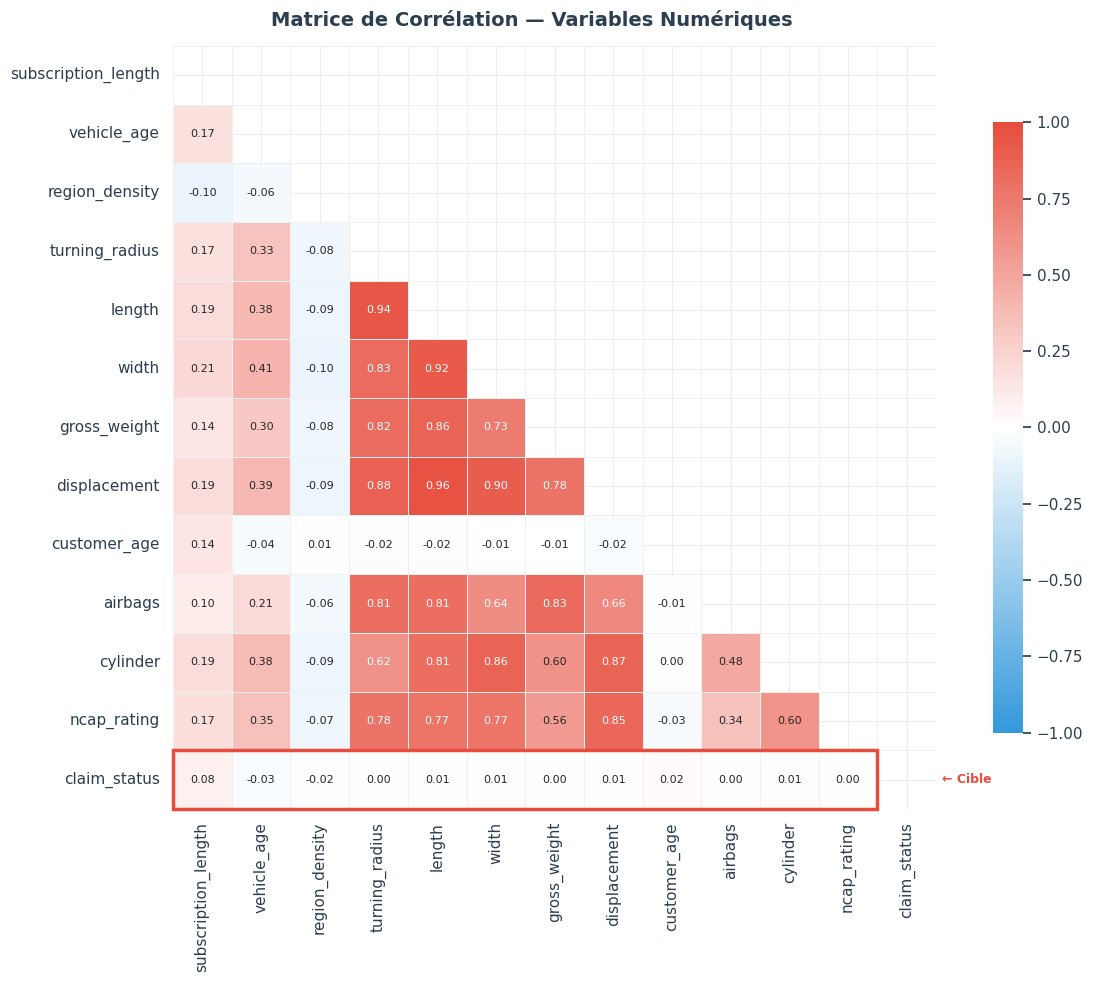

In [66]:
num_cols_corr = quanti_cols + quanti_disc + ['claim_status']
corr = df[num_cols_corr].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
fig.suptitle("Matrice de Corrélation — Variables Numériques",
             fontsize=14, fontweight='bold', color=DARK)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap=CMAP_CORP, center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='#F0F0F0',
            annot_kws={'size': 8}, ax=ax, square=True,
            cbar_kws={'shrink':0.8})
# Mettre en évidence la ligne claim_status
idx_cs = list(corr.columns).index('claim_status')
ax.add_patch(plt.Rectangle((0, idx_cs), idx_cs, 1,
             fill=False, edgecolor=RED, lw=2.5, clip_on=False))
ax.text(len(corr)+0.1, idx_cs+0.5, '← Cible',
        va='center', fontsize=9, color=RED, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Étape 2 — Preprocessing & Feature Engineering
### 2.1 Nettoyage

In [67]:
df_clean = df.copy()

# 1. Suppression de l'identifiant (non informatif)
df_clean = df_clean.drop(columns=['policy_id'])
print("✅ policy_id supprimé")

# 2. Extraction valeurs numériques de max_torque et max_power
import re
df_clean['max_torque_nm']  = df_clean['max_torque'].str.extract(r'([\d.]+)Nm').astype(float)
df_clean['max_power_bhp']  = df_clean['max_power'].str.extract(r'([\d.]+)bhp').astype(float)
df_clean = df_clean.drop(columns=['max_torque','max_power'])
print("✅ max_torque → max_torque_nm (float), max_power → max_power_bhp (float)")

# 3. Encodage variables binaires Yes/No → 0/1
yn_cols = [c for c in df_clean.columns
           if df_clean[c].dtype == object
           and set(df_clean[c].dropna().unique()) <= {'Yes','No'}]
for col in yn_cols:
    df_clean[col] = (df_clean[col] == 'Yes').astype(int)
print(f"✅ {len(yn_cols)} variables binaires Yes/No encodées en 0/1")

# 4. Encodage rear_brakes_type (Disc=1, Drum=0)
df_clean['rear_brakes_type'] = (df_clean['rear_brakes_type'] == 'Disc').astype(int)
print("✅ rear_brakes_type : Disc=1, Drum=0")

# 5. Encodage transmission_type (Automatic=1, Manual=0)
df_clean['transmission_type'] = (df_clean['transmission_type'] == 'Automatic').astype(int)
print("✅ transmission_type : Automatic=1, Manual=0")

# 6. Encodage fuel_type (ordinal : CNG=0, Diesel=1, Petrol=2)
df_clean['fuel_type'] = df_clean['fuel_type'].map({'CNG':0,'Diesel':1,'Petrol':2})
print("✅ fuel_type : CNG=0, Diesel=1, Petrol=2")

# 7. Label encoding variables multi-catégorielles
le = LabelEncoder()
for col in ['region_code','segment','model','engine_type','steering_type']:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
print("✅ LabelEncoder appliqué : region_code, segment, model, engine_type, steering_type")

print(f"\nShape après nettoyage : {df_clean.shape}")
print(f"Valeurs manquantes     : {df_clean.isnull().sum().sum()}")
print(f"Types restants         : {df_clean.dtypes.value_counts().to_dict()}")


✅ policy_id supprimé
✅ max_torque → max_torque_nm (float), max_power → max_power_bhp (float)
✅ 0 variables binaires Yes/No encodées en 0/1
✅ rear_brakes_type : Disc=1, Drum=0
✅ transmission_type : Automatic=1, Manual=0
✅ fuel_type : CNG=0, Diesel=1, Petrol=2
✅ LabelEncoder appliqué : region_code, segment, model, engine_type, steering_type

Shape après nettoyage : (58592, 40)
Valeurs manquantes     : 0
Types restants         : {dtype('int64'): 18, <StringDtype(na_value=nan)>: 17, dtype('float64'): 5}


### 2.2 Feature Engineering — Création de nouvelles variables

In [68]:
# ── 5 nouvelles variables métier ──────────────────────────────────────────────

# 1. Ratio âge conducteur / âge véhicule (conducteur jeune sur vieux véhicule = risque ?)
df_clean['age_ratio']          = df_clean['customer_age'] / (df_clean['vehicle_age'] + 1)

# 2. Score de sécurité agrégé (airbags × note NCAP)
df_clean['safety_score']       = df_clean['airbags'] * df_clean['ncap_rating']

# 3. Logarithme de la densité (forte asymétrie droite)
df_clean['log_density']        = np.log1p(df_clean['region_density'])

# 4. Puissance par cylindre (performance moteur)
df_clean['power_per_cylinder'] = df_clean['max_power_bhp'] / df_clean['cylinder']

# 5. Indicateur véhicule récent (< 2 ans)
df_clean['new_vehicle']        = (df_clean['vehicle_age'] < 2).astype(int)

new_feats = ['age_ratio','safety_score','log_density','power_per_cylinder','new_vehicle']
print("✅ Nouvelles variables créées :")
for f in new_feats:
    s = df_clean[f].describe()
    print(f"   • {f:22s}  moy={s['mean']:.2f}  std={s['std']:.2f}  min={s['min']:.2f}  max={s['max']:.2f}")

print(f"\nShape finale : {df_clean.shape}")


✅ Nouvelles variables créées :
   • age_ratio               moy=23.47  std=11.76  min=1.71  max=73.00
   • safety_score            moy=6.39  std=6.94  min=0.00  max=18.00
   • log_density             moy=9.43  std=0.95  min=5.67  max=11.20
   • power_per_cylinder      moy=21.22  std=5.62  min=13.45  max=39.45
   • new_vehicle             moy=0.68  std=0.47  min=0.00  max=1.00

Shape finale : (58592, 45)


### 2.3 Split stratifié Train / Test (80 / 20) — Avant tout fitting

In [69]:
# ORDRE CORRECT : nettoyage → feature engineering → SPLIT → imputer/scaler sur train
X = df_clean.drop(columns=['claim_status'])
y = df_clean['claim_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("=" * 55)
print(f"  X_train : {X_train.shape}  | {y_train.mean()*100:.2f}% sinistres")
print(f"  X_test  : {X_test.shape}   | {y_test.mean()*100:.2f}% sinistres")
print("=" * 55)
print("✅ Split STRATIFIÉ → même taux de sinistres dans train et test")
print("✅ Aucun fit avant le split → pas de data leakage")


  X_train : (46873, 44)  | 6.40% sinistres
  X_test  : (11719, 44)   | 6.40% sinistres
✅ Split STRATIFIÉ → même taux de sinistres dans train et test
✅ Aucun fit avant le split → pas de data leakage


### 2.4 Scaling — Uniquement pour AFD et Logit

In [70]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Identify categorical vs numeric columns
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(exclude=['object', 'category']).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

# 2. Build a preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
])

# 3. Fit on train, transform both
X_train_sc = preprocessor.fit_transform(X_train)
X_test_sc = preprocessor.transform(X_test)

# If you want DataFrames back:
feature_names = (
    num_cols + 
    list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
)
X_train_sc = pd.DataFrame(X_train_sc, columns=feature_names, index=X_train.index)
X_test_sc = pd.DataFrame(X_test_sc, columns=feature_names, index=X_test.index)

Categorical columns: ['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']
Numeric columns: ['subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'segment', 'model', 'fuel_type', 'engine_type', 'airbags', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight', 'ncap_rating', 'max_torque_nm', 'max_power_bhp', 'age_ratio', 'safety_score', 'log_density', 'power_per_cylinder', 'new_vehicle']


---
## Étape 3 — Équilibrage des Classes
### 3.1 Comparaison des stratégies

In [71]:
print("Déséquilibre avant équilibrage :")
print(f"  Classe 0 : {y_train.value_counts()[0]:,}")
print(f"  Classe 1 : {y_train.value_counts()[1]:,}")
print(f"  Ratio    : {y_train.value_counts()[0]/y_train.value_counts()[1]:.1f}:1")
print()
print("Stratégies disponibles :")
print("  • Sur-échantillonnage simple  : RandomOverSampler (duplication)")
print("  • Sous-échantillonnage simple : RandomUnderSampler (suppression)")
print("  • SMOTE                       : interpolation entre voisins (quanti)")
print("  • SMOTE-NC                    : SMOTE pour données mixtes (quanti+quali)")
print("  • SMOTETomek                  : SMOTE + nettoyage frontières (hybride)")
print()
print("→ Notre choix : SMOTETomek (meilleure frontière de décision)")


Déséquilibre avant équilibrage :
  Classe 0 : 43,875
  Classe 1 : 2,998
  Ratio    : 14.6:1

Stratégies disponibles :
  • Sur-échantillonnage simple  : RandomOverSampler (duplication)
  • Sous-échantillonnage simple : RandomUnderSampler (suppression)
  • SMOTE                       : interpolation entre voisins (quanti)
  • SMOTE-NC                    : SMOTE pour données mixtes (quanti+quali)
  • SMOTETomek                  : SMOTE + nettoyage frontières (hybride)

→ Notre choix : SMOTETomek (meilleure frontière de décision)


### 3.2 Application — SMOTETomek

  Avant  → Classe 0: 43,875 | Classe 1: 2,998
  Après  → Classe 0: 42,616 | Classe 1: 13,219
  Taux sinistres après : 23.7%


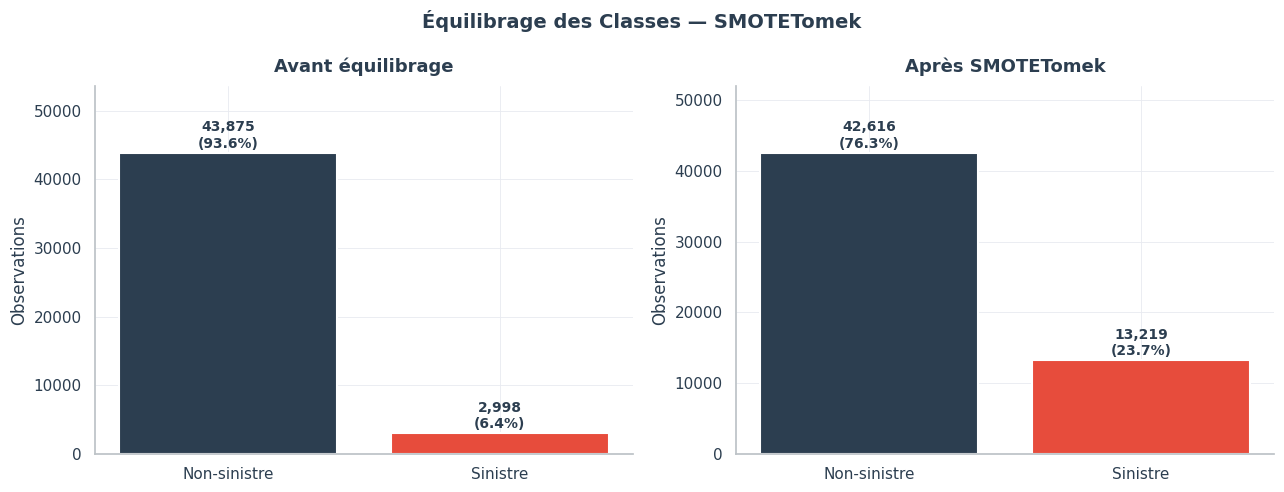

In [72]:
smt = SMOTETomek(sampling_strategy=0.33, random_state=42)

# Rééchantillonnage UNIQUEMENT sur les données scalées/encodées
X_train_bal_sc, y_train_bal = smt.fit_resample(X_train_sc, y_train)

# Reconstruction en DataFrame avec les noms de colonnes de X_train_sc
X_train_bal = pd.DataFrame(X_train_bal_sc, 
                               columns=X_train_sc.columns, 
                               index=range(len(X_train_bal_sc)))

print("=" * 55)
print(f"  Avant  → Classe 0: {y_train.value_counts()[0]:,} | Classe 1: {y_train.value_counts()[1]:,}")
print(f"  Après  → Classe 0: {y_train_bal.value_counts()[0]:,} | Classe 1: {y_train_bal.value_counts()[1]:,}")
print(f"  Taux sinistres après : {y_train_bal.mean()*100:.1f}%")
print("=" * 55)

# ── Visualisation avant/après ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Équilibrage des Classes — SMOTETomek",
             fontsize=14, fontweight='bold', color=DARK)
for ax, y_c, title in [(axes[0], y_train, 'Avant équilibrage'),
                        (axes[1], y_train_bal, 'Après SMOTETomek')]:
    cnts = y_c.value_counts().sort_index()
    bars = ax.bar(['Non-sinistre','Sinistre'], cnts.values,
                  color=[DARK, RED], edgecolor='white', linewidth=1.5)
    ax.set_title(title, pad=10)
    ax.set_ylabel("Observations")
    ax.set_ylim(0, cnts.max()*1.22)
    for bar, cnt in zip(bars, cnts.values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+300,
            f'{cnt:,}\n({cnt/cnts.sum()*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', color=DARK, fontsize=10)
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### 3.3 Note SMOTE-NC — Pour données mixtes

In [73]:
# ── SMOTE-NC : adapté aux datasets mixtes (quantitatif + qualitatif) ──────────
# Dans notre pipeline, toutes les variables ont été encodées numériquement.
# SMOTE-NC est utile AVANT encodage, sur les données brutes mixtes.
#
# Exemple d'utilisation (illustratif) :
# cat_idx = [list(X_train.columns).index(c) for c in ['segment','fuel_type',...]]
# smotenc = SMOTENC(categorical_features=cat_idx, sampling_strategy=0.33,
#                   random_state=42)
# X_bal_nc, y_bal_nc = smotenc.fit_resample(X_train_raw_mixed, y_train)
#
# Avantage : génère des modalités cohérentes pour les quali (pas d'interpolation)
# Inconvénient : plus lent, nécessite de garder les colonnes non encodées

print("ℹ️  SMOTE-NC applicable sur données mixtes (avant encodage complet)")
print("   Notre choix final : SMOTETomek sur données toutes encodées ✅")


ℹ️  SMOTE-NC applicable sur données mixtes (avant encodage complet)
   Notre choix final : SMOTETomek sur données toutes encodées ✅


---
## Étape 4 — Sélection des Variables
### 4.1 Méthode Filtre — SelectKBest (ANOVA F-score)

✅ SelectKBest → 24 features significatives (p < 0.05)


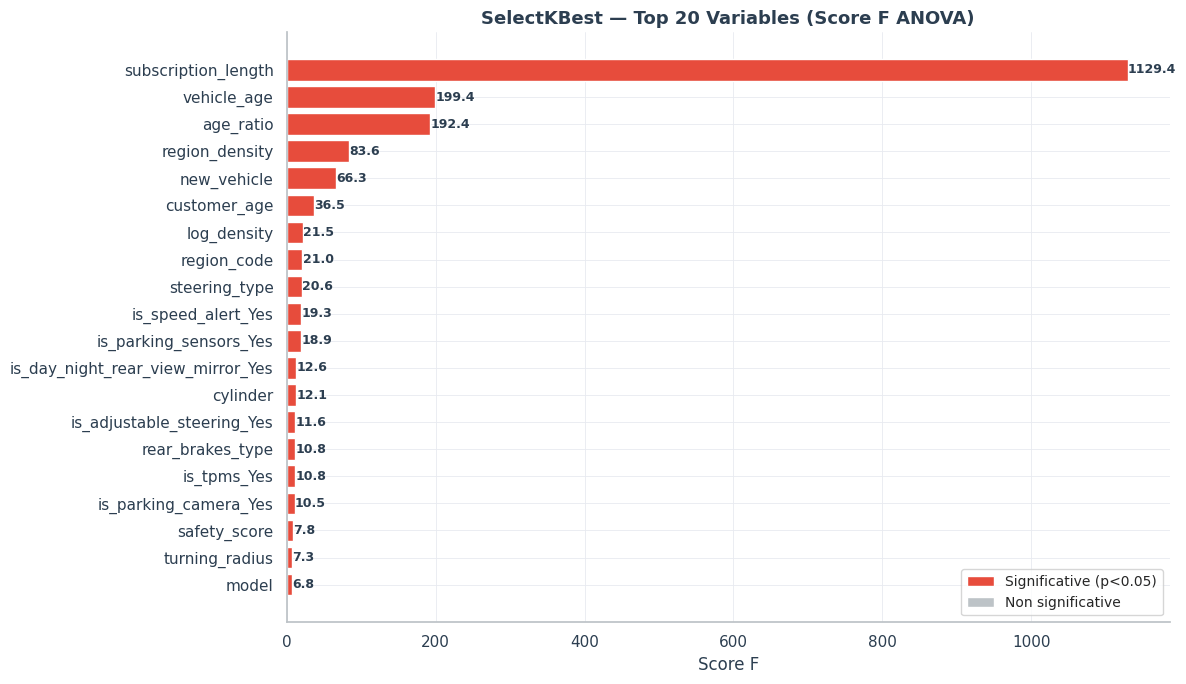

In [74]:
# F = Variance inter-classes / Variance intra-classes
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_bal, y_train_bal)

scores_df = pd.DataFrame({
    'Feature' : X_train_bal.columns,
    'F_score' : selector.scores_,
    'p_value' : selector.pvalues_
}).sort_values('F_score', ascending=False).reset_index(drop=True)

kbest_features = scores_df[scores_df['p_value'] < 0.05]['Feature'].tolist()
print(f"✅ SelectKBest → {len(kbest_features)} features significatives (p < 0.05)")

# Visualisation Top 20
fig, ax = plt.subplots(figsize=(12, 7))
top20  = scores_df.head(20)
colors = [RED if p < 0.05 else GRAY for p in top20['p_value']]
bars   = ax.barh(top20['Feature'][::-1], top20['F_score'][::-1],
                 color=colors[::-1], edgecolor='white', linewidth=1)
for bar, v in zip(bars, top20['F_score'][::-1]):
    ax.text(v+0.3, bar.get_y()+bar.get_height()/2,
            f'{v:.1f}', va='center', fontsize=9, fontweight='bold', color=DARK)
ax.set_title("SelectKBest — Top 20 Variables (Score F ANOVA)",
             fontsize=13, fontweight='bold', color=DARK)
ax.set_xlabel("Score F")
els = [mpatches.Patch(facecolor=RED, label='Significative (p<0.05)'),
       mpatches.Patch(facecolor=GRAY, label='Non significative')]
ax.legend(handles=els, fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


### 4.2 Méthode Wrapper — RFECV

⏳ Exécution RFECV en cours...


✅ RFECV terminé
   Nombre optimal de features : 10
   Meilleur AUC-CV : 0.8886
   Features sélectionnées : ['subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'model', 'displacement', 'length', 'age_ratio', 'log_density']


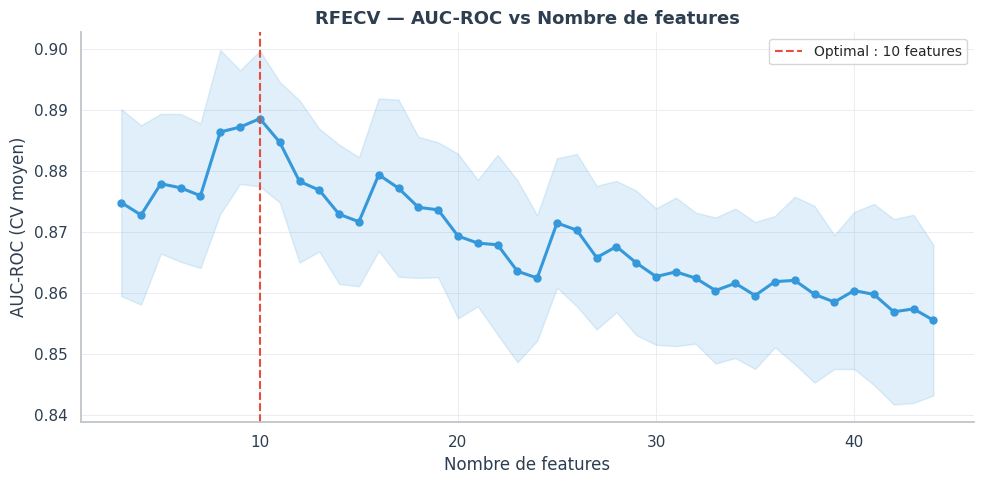

In [75]:
print("⏳ Exécution RFECV en cours...")

# Sous-échantillon pour accélérer
idx_s  = np.random.RandomState(42).choice(len(X_train_bal), size=12000, replace=False)
X_rfe  = X_train_bal.iloc[idx_s]
y_rfe  = y_train_bal.iloc[idx_s]

rfecv = RFECV(
    estimator              = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1),
    step                   = 1,
    cv                     = StratifiedKFold(5),
    scoring                = 'roc_auc',
    min_features_to_select = 3,
    n_jobs                 = -1
)
rfecv.fit(X_rfe, y_rfe)
rfecv_features = X_train_bal.columns[rfecv.support_].tolist()

print(f"✅ RFECV terminé")
print(f"   Nombre optimal de features : {rfecv.n_features_}")
print(f"   Meilleur AUC-CV : {rfecv.cv_results_['mean_test_score'].max():.4f}")
print(f"   Features sélectionnées : {rfecv_features}")

# Courbe RFECV
fig, ax = plt.subplots(figsize=(10, 5))
n_range = range(rfecv.min_features_to_select,
                rfecv.min_features_to_select + len(rfecv.cv_results_['mean_test_score']))
scores_mean = rfecv.cv_results_['mean_test_score']
scores_std  = rfecv.cv_results_['std_test_score']
ax.plot(n_range, scores_mean, color=BLUE, linewidth=2.2, marker='o', markersize=5)
ax.fill_between(n_range, scores_mean - scores_std, scores_mean + scores_std,
                alpha=0.15, color=BLUE)
ax.axvline(rfecv.n_features_, color=RED, linestyle='--',
           label=f'Optimal : {rfecv.n_features_} features')
ax.set_title("RFECV — AUC-ROC vs Nombre de features",
             fontsize=13, fontweight='bold', color=DARK)
ax.set_xlabel("Nombre de features")
ax.set_ylabel("AUC-ROC (CV moyen)")
ax.legend(fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


### 4.3 Intersection finale — SelectKBest ∩ RFECV

In [77]:
# Intersection des deux méthodes
intersection = list(set(kbest_features) & set(rfecv_features))

print(f"SelectKBest : {len(kbest_features)} features")
print(f"RFECV       : {len(rfecv_features)} features → {rfecv_features}")
print(f"Intersection : {len(intersection)} features → {sorted(intersection)}")

# Enrichissement : top 12 SelectKBest ∪ RFECV (garantit assez de features)
top12_kbest   = scores_df.head(12)['Feature'].tolist()
final_features = sorted(list(set(top12_kbest) | set(rfecv_features)))

print(f"\n✅ Features finales retenues ({len(final_features)}) :")
for f in final_features:
    score = scores_df[scores_df['Feature']==f]['F_score'].values
    print(f"   • {f:30s}  F={score[0]:.1f}" if len(score)>0 else f"   • {f}")

X_train_f    = X_train_bal[final_features]
X_test_f     = X_test_sc[final_features]
X_train_f_sc = X_train_bal_sc[final_features]
X_test_f_sc  = X_test_sc[final_features]

print(f"\n  X_train_final : {X_train_f.shape}")
print(f"  X_test_final  : {X_test_f.shape}")


SelectKBest : 24 features
RFECV       : 10 features → ['subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'model', 'displacement', 'length', 'age_ratio', 'log_density']
Intersection : 8 features → ['age_ratio', 'customer_age', 'log_density', 'model', 'region_code', 'region_density', 'subscription_length', 'vehicle_age']

✅ Features finales retenues (15) :
   • age_ratio                       F=192.4
   • customer_age                    F=36.5
   • displacement                    F=0.1
   • is_day_night_rear_view_mirror_Yes  F=12.6
   • is_parking_sensors_Yes          F=18.9
   • is_speed_alert_Yes              F=19.3
   • length                          F=0.3
   • log_density                     F=21.5
   • model                           F=6.8
   • new_vehicle                     F=66.3
   • region_code                     F=21.0
   • region_density                  F=83.6
   • steering_type                   F=20.6
   • subscription_length         

---
## Étape 5 — Modélisation & Fine-tuning
### 5.1 Définition des modèles

In [78]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Sous-échantillon 8 000 obs pour SVM et KNN (complexité O(n²))
n_svm = 8000
idx_svm  = np.random.RandomState(42).choice(len(X_train_f_sc), n_svm, replace=False)
X_svm    = X_train_f_sc.iloc[idx_svm]
y_svm    = y_train_bal.iloc[idx_svm]

# ── Grilles d'hyperparamètres ─────────────────────────────────────────────────
MODEL_CONFIGS = {
    # (estimateur, grille, X_train, X_test, y_train)
    "AFD (LDA)": (
        LinearDiscriminantAnalysis(),
        {'solver': ['svd','lsqr'], 'shrinkage': [None,'auto',0.1,0.5]},
        X_train_f_sc, X_test_f_sc, y_train_bal, 'grid'
    ),
    "Logit": (
        LogisticRegression(max_iter=1000),
        {'C':[0.01,0.1,1,10], 'penalty':['l1','l2'],
         'class_weight':[None,'balanced'], 'solver':['liblinear']},
        X_train_f_sc, X_test_f_sc, y_train_bal, 'grid'
    ),
    "Arbre": (
        DecisionTreeClassifier(random_state=42),
        {'max_depth':[3,5,10,None], 'min_samples_leaf':[5,10,20],
         'criterion':['gini','entropy'], 'class_weight':[None,'balanced']},
        X_train_f, X_test_f, y_train_bal, 'grid'
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {'n_estimators':[100,200], 'max_depth':[10,None],
         'min_samples_leaf':[1,5], 'class_weight':['balanced_subsample']},
        X_train_f, X_test_f, y_train_bal, 'random'
    ),
    "XGBoost": (
        XGBClassifier(random_state=42, eval_metric='logloss',
                      verbosity=0, n_jobs=-1),
        {'n_estimators':[100,200], 'max_depth':[3,6],
         'learning_rate':[0.05,0.1], 'scale_pos_weight':[5,10]},
        X_train_f, X_test_f, y_train_bal, 'random'
    ),
    "LightGBM": (
        LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
        {'n_estimators':[100,200], 'max_depth':[5,-1],
         'learning_rate':[0.05,0.1], 'class_weight':[None,'balanced']},
        X_train_f, X_test_f, y_train_bal, 'random'
    ),
    "SVM": (
        SVC(probability=True, random_state=42, kernel='rbf'),
        {'C':[0.1,1,10], 'class_weight':[None,'balanced']},
        X_svm, X_test_f_sc, y_svm, 'grid'
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=-1),
        {'n_neighbors':[11,21,51], 'weights':['uniform','distance']},
        X_svm, X_test_f_sc, y_svm, 'grid'
    ),
}

print("✅ Modèles configurés :")
for name, cfg in MODEL_CONFIGS.items():
    n_comb = 1
    for v in cfg[1].values(): n_comb *= len(v)
    print(f"   • {name:15s} {cfg[5].upper():6s} | {n_comb} combinaisons")


✅ Modèles configurés :
   • AFD (LDA)       GRID   | 8 combinaisons
   • Logit           GRID   | 16 combinaisons
   • Arbre           GRID   | 48 combinaisons
   • Random Forest   RANDOM | 8 combinaisons
   • XGBoost         RANDOM | 16 combinaisons
   • LightGBM        RANDOM | 16 combinaisons
   • SVM             GRID   | 6 combinaisons
   • KNN             GRID   | 6 combinaisons


### 5.2 Fine-tuning — GridSearchCV / RandomizedSearchCV

In [79]:
best_models   = {}
results_rows  = []

for name, (est, grid, X_tr, X_te, y_tr, method) in MODEL_CONFIGS.items():
    print(f"\n🔄 {name} ...", end=' ', flush=True)

    y_tr_fit = y_tr.iloc[:len(X_tr)] if len(X_tr) < len(y_tr) else y_tr

    if method == 'random':
        search = RandomizedSearchCV(est, grid, n_iter=10, cv=cv5,
                                    scoring='roc_auc', n_jobs=-1,
                                    random_state=42, refit=True, verbose=0)
    else:
        search = GridSearchCV(est, grid, cv=cv5, scoring='roc_auc',
                              n_jobs=-1, refit=True, verbose=0)

    search.fit(X_tr, y_tr_fit)
    model = search.best_estimator_

    # Seuil optimal (Youden J)
    y_prob = model.predict_proba(X_te)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    best_thr = thresholds[np.argmax(tpr - fpr)]
    y_pred   = (y_prob >= best_thr).astype(int)

    # Métriques
    auc  = roc_auc_score(y_test, y_prob)
    aucpr= average_precision_score(y_test, y_prob)
    rep  = classification_report(y_test, y_pred, output_dict=True)
    rec1 = rep['1']['recall']
    pre1 = rep['1']['precision']
    f1_1 = rep['1']['f1-score']
    bacc = (rep['1']['recall'] + rep['0']['recall']) / 2

    best_models[name] = dict(model=model, proba=y_prob, pred=y_pred,
                              thr=best_thr, fpr=fpr, tpr=tpr, X_te=X_te)
    results_rows.append(dict(Modèle=name, AUC_ROC=round(auc,4),
                             AUC_PR=round(aucpr,4),
                             Rappel=round(rec1,4), Précision=round(pre1,4),
                             F1=round(f1_1,4), BalAcc=round(bacc,4),
                             Seuil=round(best_thr,3)))
    print(f"✅  AUC={auc:.4f} | Rappel={rec1:.3f} | Seuil={best_thr:.3f}")

results_df = pd.DataFrame(results_rows).sort_values('AUC_ROC', ascending=False)
print("\n" + "="*60)
print(results_df.to_string(index=False))



🔄 AFD (LDA) ... ✅  AUC=0.6150 | Rappel=0.723 | Seuil=0.213

🔄 Logit ... ✅  AUC=0.6141 | Rappel=0.731 | Seuil=0.212

🔄 Arbre ... ✅  AUC=0.5575 | Rappel=0.392 | Seuil=0.244

🔄 Random Forest ... ✅  AUC=0.5899 | Rappel=0.503 | Seuil=0.078

🔄 XGBoost ... ✅  AUC=0.6442 | Rappel=0.648 | Seuil=0.322

🔄 LightGBM ... ✅  AUC=0.6402 | Rappel=0.692 | Seuil=0.184

🔄 SVM ... ✅  AUC=0.6322 | Rappel=0.693 | Seuil=0.201

🔄 KNN ... ✅  AUC=0.5824 | Rappel=0.405 | Seuil=0.322

       Modèle  AUC_ROC  AUC_PR  Rappel  Précision     F1  BalAcc  Seuil
      XGBoost   0.6442  0.1015  0.6480     0.0985 0.1709  0.6212  0.322
     LightGBM   0.6402  0.0988  0.6920     0.0923 0.1630  0.6135  0.184
          SVM   0.6322  0.0949  0.6933     0.0919 0.1623  0.6124  0.201
    AFD (LDA)   0.6150  0.0887  0.7227     0.0833 0.1494  0.5896  0.213
        Logit   0.6141  0.0883  0.7307     0.0838 0.1503  0.5922  0.212
Random Forest   0.5899  0.0850  0.5027     0.0867 0.1480  0.5704  0.078
          KNN   0.5824  0.0888  0.

### 5.3 PyCaret — Comparaison automatique des modèles

In [85]:
try:
    from pycaret.classification import (
        setup as pc_setup, compare_models, pull, finalize_model, predict_model
    )
except ModuleNotFoundError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycaret"], check=True)
    from pycaret.classification import (
        setup as pc_setup, compare_models, pull, finalize_model, predict_model
    )

pc_data = X_train_bal.copy()
pc_data["claim_status"] = y_train_bal.values

pc_setup(
    data=pc_data,
    target="claim_status",
    session_id=42,
    fold=5,
    fold_strategy="stratifiedkfold",
    verbose=False,
    html=False,
)

best_pc = compare_models(
    include=["lda", "lr", "dt", "rf", "xgboost", "lightgbm", "svm", "knn"],
    sort="AUC",
    n_select=3,
    verbose=True,
)

pc_results = pull()
print("\n✅ PyCaret — Résultats :")
cols = [c for c in ["Model", "AUC", "Recall", "Prec.", "F1", "Kappa"] if c in pc_results.columns]
print(pc_results[cols].to_string(index=False))

from pycaret.classification import (setup as pc_setup, compare_models,
                                    pull, finalize_model, predict_model)

# Setup PyCaret sur le dataset équilibré
pc_data = X_train_bal.copy()
pc_data['claim_status'] = y_train_bal.values

pc_setup(
    data          = pc_data,
    target        = 'claim_status',
    session_id    = 42,
    fold          = 5,
    fold_strategy = 'stratifiedkfold',
    metric_target = 'AUC',
    verbose       = False,
    html          = False,
)

# Comparaison des modèles
best_pc = compare_models(
    include  = ['lda','lr','dt','rf','xgboost','lightgbm','svm','knn'],
    sort     = 'AUC',
    n_select = 3,
    verbose  = True
)
pc_results = pull()
print("\n✅ PyCaret — Résultats :")
print(pc_results[['Model','AUC','Recall','Prec.','F1','Kappa']].to_string())


CalledProcessError: Command '['c:\\Users\\user\\AppData\\Local\\Python\\pythoncore-3.14-64\\python.exe', '-m', 'pip', 'install', '-q', 'pycaret']' returned non-zero exit status 1.

---
## Étape 6 — Évaluation Comparative
### 6.1 Tableau des performances

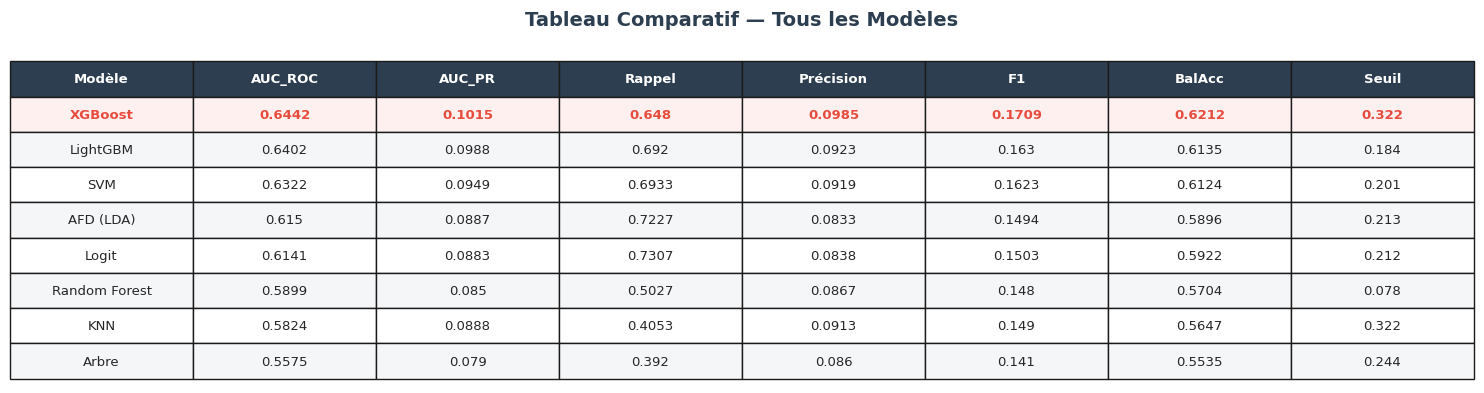

In [86]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.axis('off')
fig.suptitle("Tableau Comparatif — Tous les Modèles",
             fontsize=14, fontweight='bold', color=DARK)
cols_show = ['Modèle','AUC_ROC','AUC_PR','Rappel','Précision','F1','BalAcc','Seuil']
data_tab  = results_df[cols_show].values.tolist()
tbl = ax.table(cellText=data_tab, colLabels=cols_show,
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1, 2.0)
for j in range(len(cols_show)):
    tbl[(0,j)].set_facecolor(DARK)
    tbl[(0,j)].set_text_props(color='white', fontweight='bold')
best_idx = results_df['AUC_ROC'].idxmax()
for i, ridx in enumerate(results_df.index, 1):
    bg = '#F4F6F8' if i%2==0 else WHITE
    for j in range(len(cols_show)):
        tbl[(i,j)].set_facecolor(bg)
    if ridx == best_idx:
        for j in range(len(cols_show)):
            tbl[(i,j)].set_facecolor('#FFF0F0')
            tbl[(i,j)].set_text_props(color=RED, fontweight='bold')
plt.tight_layout()
plt.show()


### 6.2 Courbes ROC

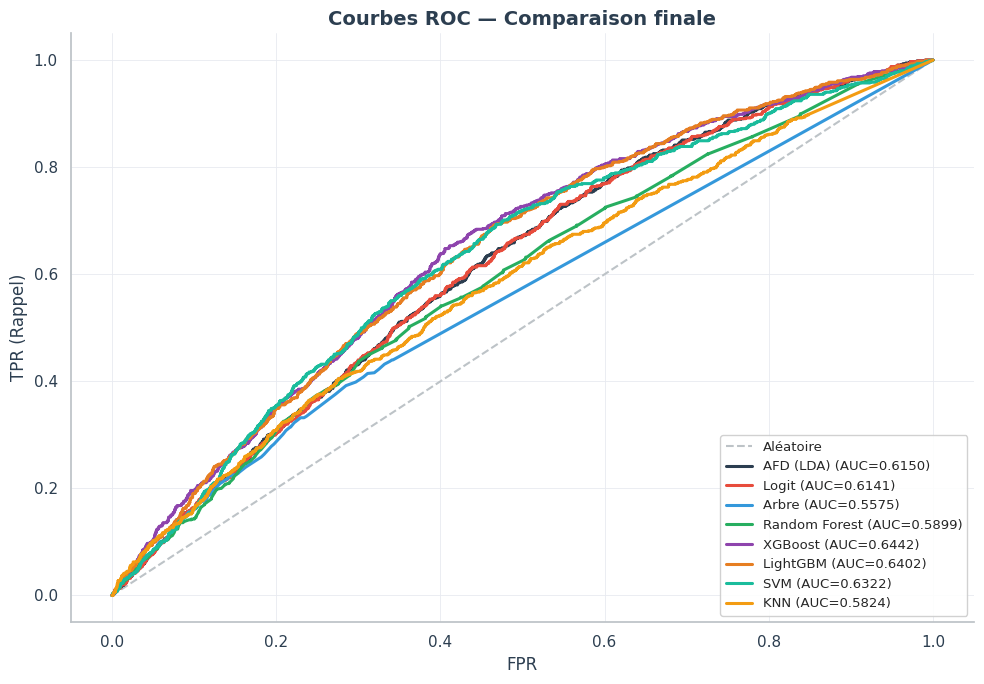

In [87]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot([0,1],[0,1], color=GRAY, linestyle='--', lw=1.5, label='Aléatoire')
pal8 = [DARK, RED, BLUE, '#27AE60', '#8E44AD', '#E67E22', '#1ABC9C', '#F39C12']

for (name, info), c in zip(best_models.items(), pal8):
    auc = roc_auc_score(y_test, info['proba'])
    ax.plot(info['fpr'], info['tpr'], label=f"{name} (AUC={auc:.4f})",
            lw=2.2, color=c)

ax.set_title("Courbes ROC — Comparaison finale",
             fontsize=14, fontweight='bold', color=DARK)
ax.set_xlabel("FPR"); ax.set_ylabel("TPR (Rappel)")
ax.legend(loc='lower right', fontsize=9.5, framealpha=0.9)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


### 6.3 Courbes Précision-Rappel

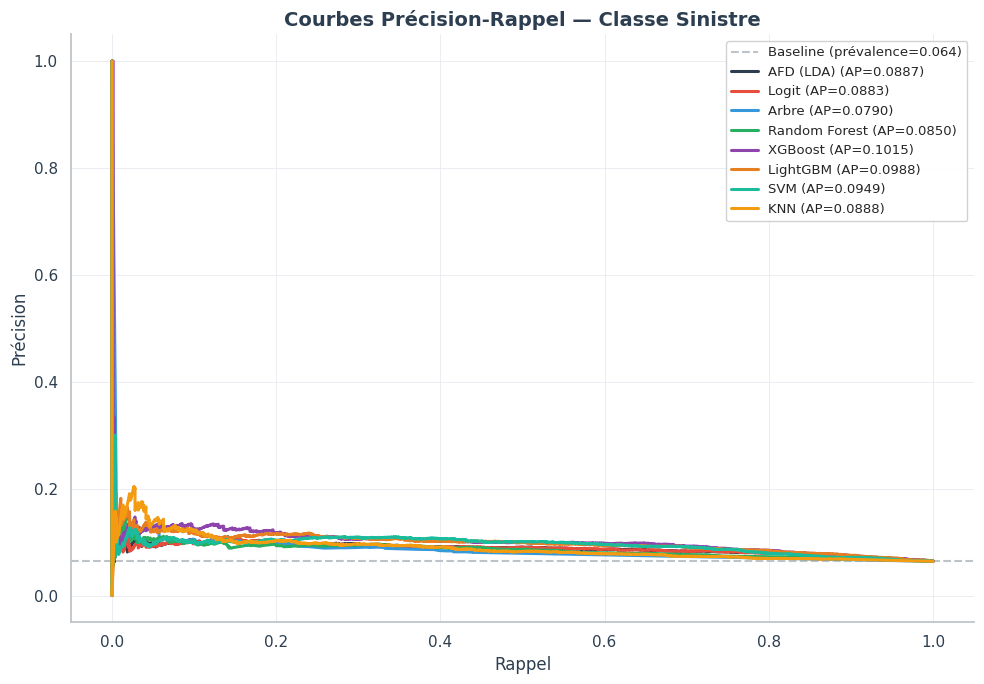

In [88]:
fig, ax = plt.subplots(figsize=(10, 7))
baseline = y_test.mean()
ax.axhline(baseline, color=GRAY, linestyle='--', lw=1.5,
           label=f'Baseline (prévalence={baseline:.3f})')

for (name, info), c in zip(best_models.items(), pal8):
    p, r, _ = precision_recall_curve(y_test, info['proba'])
    ap = average_precision_score(y_test, info['proba'])
    ax.plot(r, p, label=f"{name} (AP={ap:.4f})", lw=2.2, color=c)

ax.set_title("Courbes Précision-Rappel — Classe Sinistre",
             fontsize=14, fontweight='bold', color=DARK)
ax.set_xlabel("Rappel"); ax.set_ylabel("Précision")
ax.legend(loc='upper right', fontsize=9.5, framealpha=0.9)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


### 6.4 Matrices de confusion — Seuil Youden J

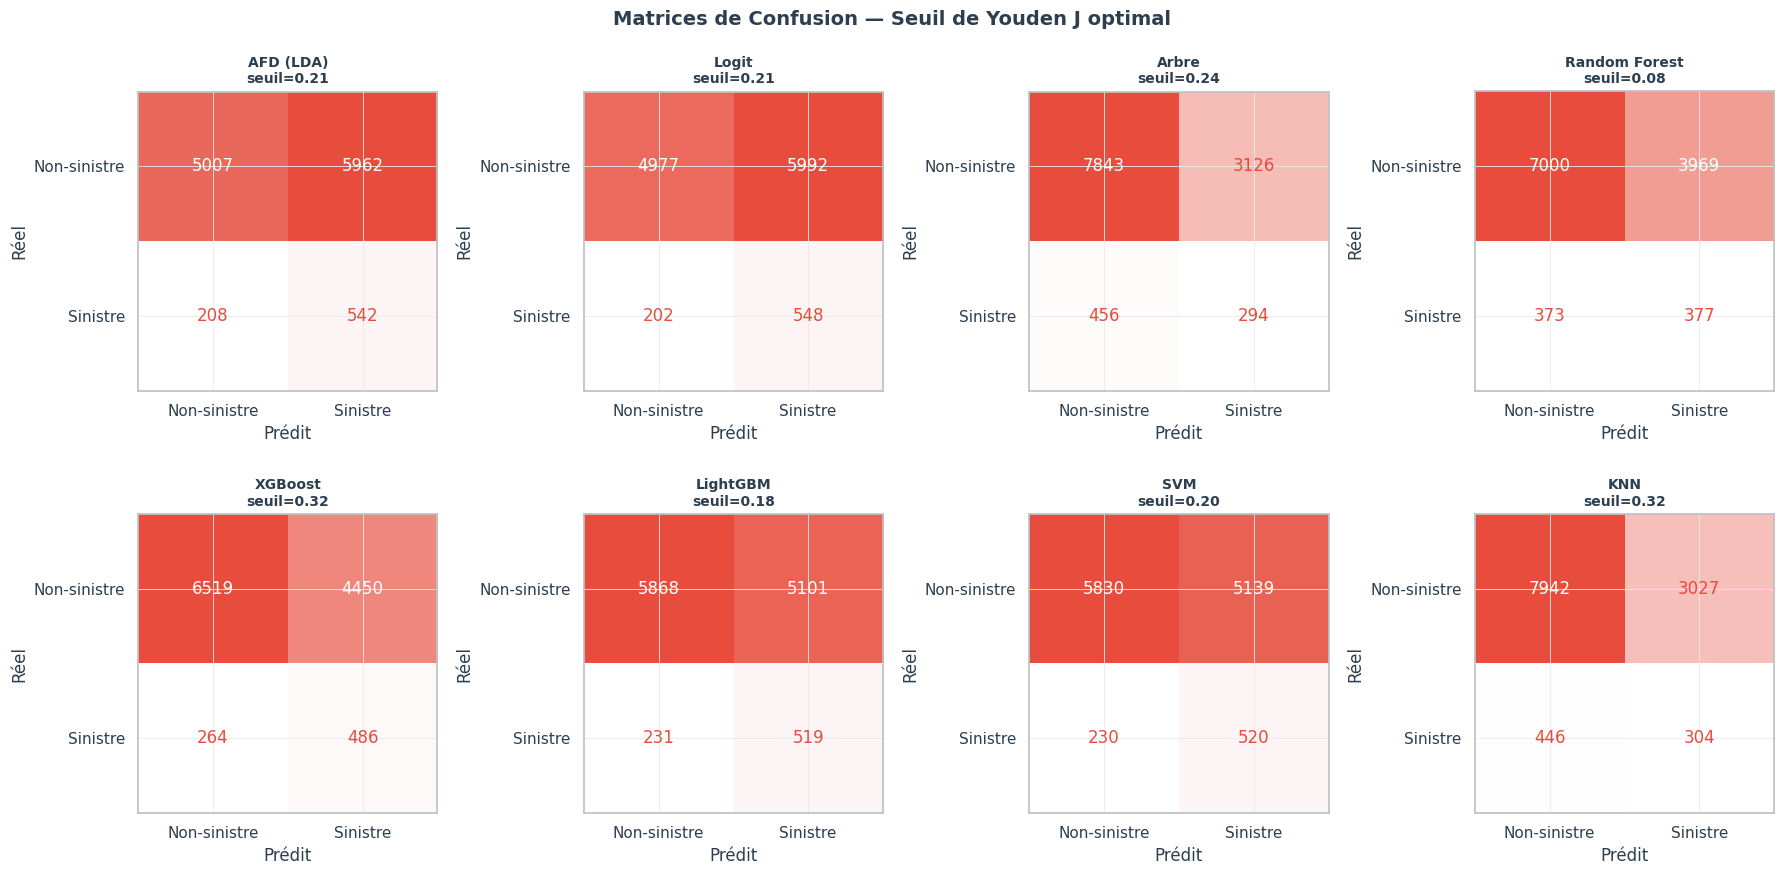

In [89]:
n_m = len(best_models)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle("Matrices de Confusion — Seuil de Youden J optimal",
             fontsize=14, fontweight='bold', color=DARK)
for ax, (name, info) in zip(axes.flat, best_models.items()):
    cm   = confusion_matrix(y_test, info['pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-sinistre','Sinistre'])
    disp.plot(ax=ax, colorbar=False,
              cmap=LinearSegmentedColormap.from_list('cm',[WHITE,RED],N=100))
    ax.set_title(f"{name}\nseuil={info['thr']:.2f}",
                 fontsize=10, fontweight='bold', color=DARK)
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel')
plt.tight_layout()
plt.show()


### 6.5 Bootstrap IC 95% sur l'AUC

In [90]:
np.random.seed(42)
B = 500

print("Bootstrap IC 95% sur l'AUC-ROC (B=500) :")
print("-" * 50)
for name, info in best_models.items():
    aucs_boot = []
    n_te = len(y_test)
    for _ in range(B):
        idx = np.random.choice(n_te, n_te, replace=True)
        if len(np.unique(y_test.values[idx])) < 2:
            continue
        aucs_boot.append(roc_auc_score(y_test.values[idx],
                                       info['proba'][idx]))
    lo, hi = np.percentile(aucs_boot, [2.5, 97.5])
    print(f"  {name:15s} AUC={roc_auc_score(y_test,info['proba']):.4f}"
          f"  IC95% [{lo:.4f} ; {hi:.4f}]")


Bootstrap IC 95% sur l'AUC-ROC (B=500) :
--------------------------------------------------
  AFD (LDA)       AUC=0.6150  IC95% [0.5949 ; 0.6352]
  Logit           AUC=0.6141  IC95% [0.5958 ; 0.6347]
  Arbre           AUC=0.5575  IC95% [0.5393 ; 0.5760]
  Random Forest   AUC=0.5899  IC95% [0.5700 ; 0.6110]
  XGBoost         AUC=0.6442  IC95% [0.6255 ; 0.6649]
  LightGBM        AUC=0.6402  IC95% [0.6211 ; 0.6597]
  SVM             AUC=0.6322  IC95% [0.6130 ; 0.6536]
  KNN             AUC=0.5824  IC95% [0.5645 ; 0.6041]


---
## Étape 7 — Interprétabilité — SHAP
### 7.1 Importance MDI vs Permutation (Random Forest)

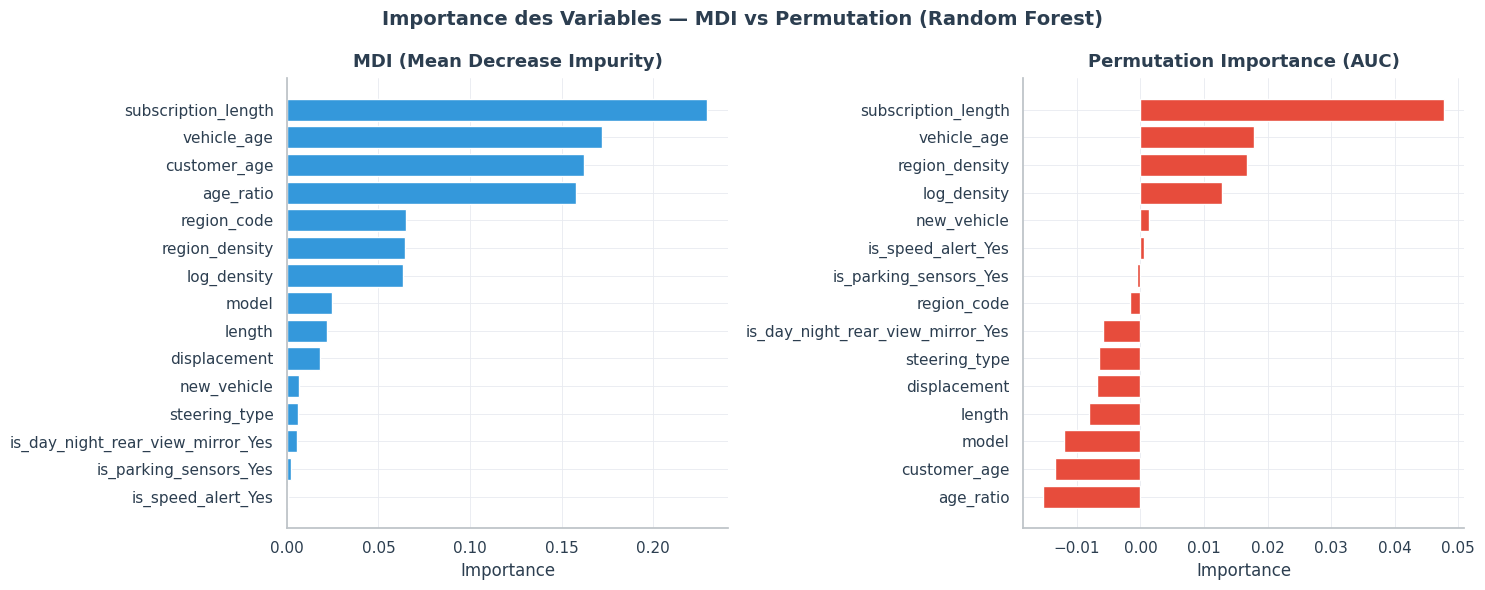

In [91]:
rf_model = best_models['Random Forest']['model']

# MDI
mdi_imp = pd.Series(rf_model.feature_importances_, index=final_features
                    ).sort_values(ascending=False)

# Permutation importance (sur test)
perm = permutation_importance(rf_model, X_test_f, y_test,
                              n_repeats=10, random_state=42,
                              scoring='roc_auc', n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=final_features
                     ).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Importance des Variables — MDI vs Permutation (Random Forest)",
             fontsize=14, fontweight='bold', color=DARK)

for ax, imp, title, color in [
    (axes[0], mdi_imp,  'MDI (Mean Decrease Impurity)',  BLUE),
    (axes[1], perm_imp, 'Permutation Importance (AUC)',  RED)
]:
    ax.barh(imp.index[::-1], imp.values[::-1],
            color=color, edgecolor='white', linewidth=1)
    ax.set_title(title, pad=8)
    ax.set_xlabel("Importance")
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()


### 7.2 SHAP Summary Plot — Bar (importance globale)

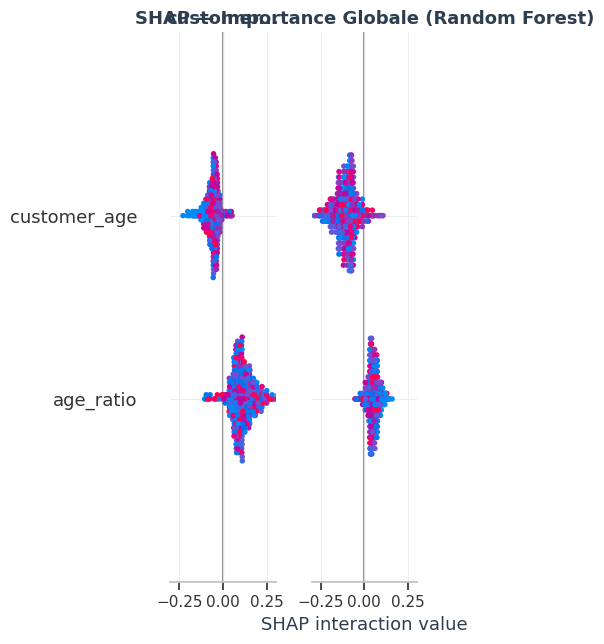

In [92]:
X_shap = X_test_f.sample(500, random_state=42)
explainer = shap.TreeExplainer(rf_model)
sv        = explainer.shap_values(X_shap)
# Pour classification binaire, prendre classe 1
sv1 = sv[1] if isinstance(sv, list) else sv

shap.summary_plot(sv1, X_shap, plot_type='bar', color=RED, show=False)
plt.title("SHAP — Importance Globale (Random Forest)",
          fontsize=13, fontweight='bold', color=DARK)
plt.tight_layout()
plt.show()


### 7.3 SHAP Beeswarm Plot — Direction & intensité des effets

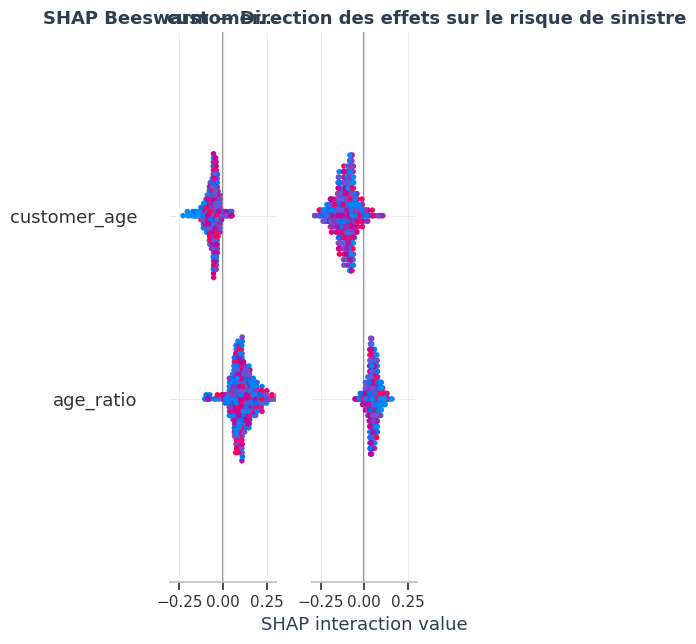

In [93]:
shap.summary_plot(sv1, X_shap, plot_type='dot', show=False)
plt.title("SHAP Beeswarm — Direction des effets sur le risque de sinistre",
          fontsize=13, fontweight='bold', color=DARK)
plt.tight_layout()
plt.show()
# Lecture : rouge = valeur haute de la feature
#           droite = augmente le risque de sinistre
#           gauche = diminue le risque de sinistre


### 7.4 SHAP Waterfall Plot — Explication d'une prédiction individuelle

In [94]:
# Prendre un vrai sinistre prédit correctement
mask_sin = (y_test == 1).values
probas   = best_models['Random Forest']['proba']
thr      = best_models['Random Forest']['thr']

# Indices test dans X_shap
X_shap_idx = X_shap.index.tolist()
y_test_r   = y_test.reset_index(drop=True)

# Chercher un sinistre dans X_shap
for i, idx in enumerate(X_shap_idx):
    pos_test = list(X_test_f.index).index(idx)
    if y_test.values[pos_test] == 1 and probas[pos_test] >= thr:
        case_pos = i
        break

expl = shap.Explanation(
    values      = sv1[case_pos],
    base_values = explainer.expected_value[1] if isinstance(explainer.expected_value, list)
                  else explainer.expected_value,
    data        = X_shap.iloc[case_pos].values,
    feature_names = list(X_shap.columns)
)
shap.waterfall_plot(expl, show=False)
plt.title("SHAP Waterfall — Explication d'un sinistre prédit",
          fontsize=13, fontweight='bold', color=DARK)
plt.tight_layout()
plt.show()


ValueError: The waterfall plot can currently only plot a single explanation, but a matrix of explanations (shape (15, 2)) was passed! Perhaps try `shap.plots.waterfall(shap_values[0])` or for multi-output models, try `shap.plots.waterfall(shap_values[0, 0])`.

### 7.5 SHAP Dependence Plot — Effet non-linéaire

In [95]:
# Top 2 features selon SHAP
top2 = pd.Series(np.abs(sv1).mean(axis=0),
                 index=X_shap.columns).sort_values(ascending=False).index[:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("SHAP Dependence Plots — Top 2 variables",
             fontsize=14, fontweight='bold', color=DARK)
for ax, feat in zip(axes, top2):
    shap.dependence_plot(feat, sv1, X_shap, ax=ax, show=False,
                         dot_size=8, alpha=0.5)
    ax.set_title(f"Effet de : {feat}", fontsize=11, fontweight='bold', color=DARK)
plt.tight_layout()
plt.show()


ValueError: Data must be 1-dimensional, got ndarray of shape (15, 2) instead

### 7.6 SHAP — Régression Logistique (Odds Ratios + SHAP Linear)

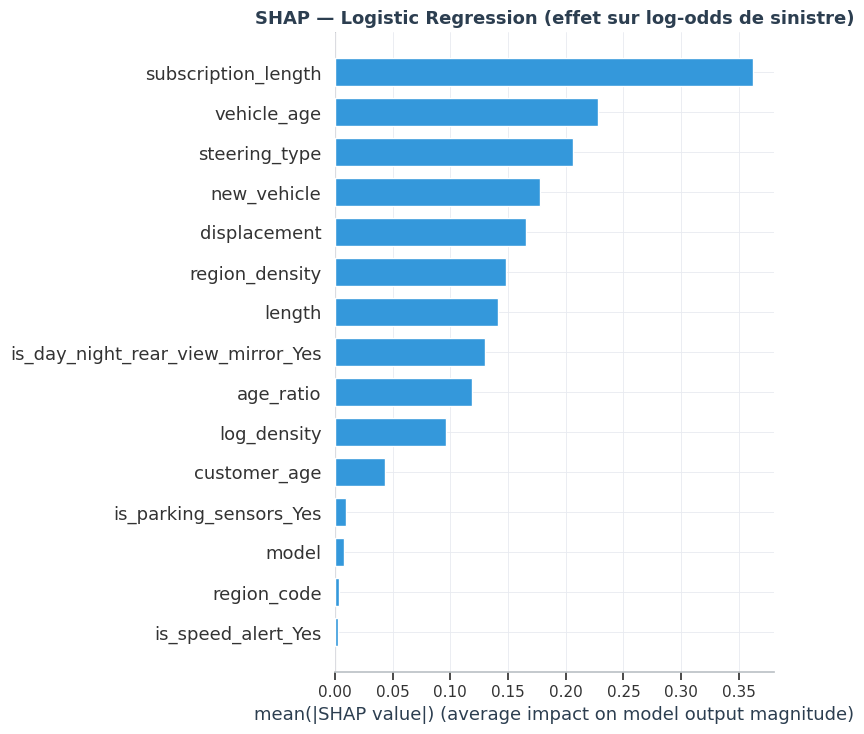

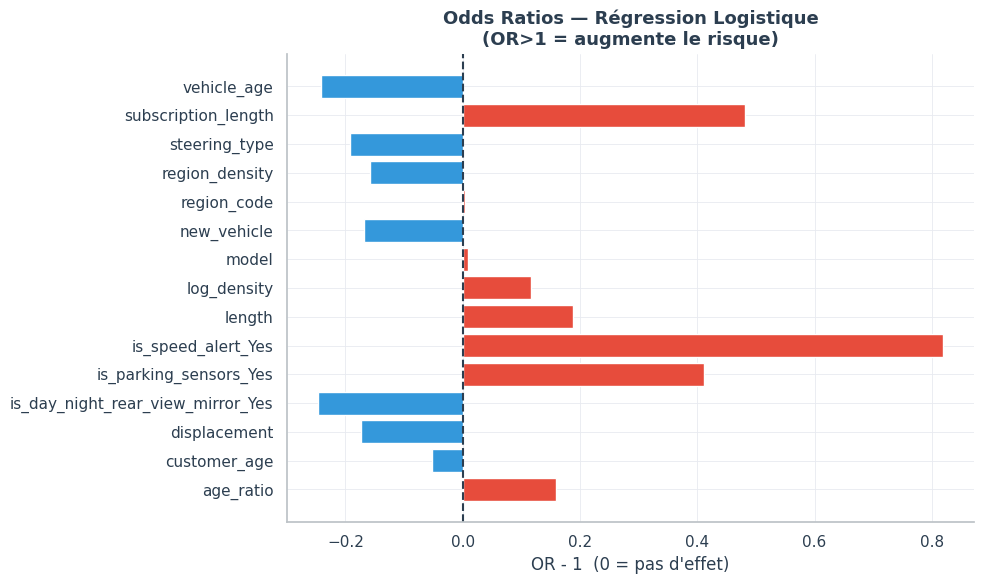

In [96]:
logit_model = best_models['Logit']['model']

# SHAP Linear
X_shap_sc  = X_test_f_sc.sample(500, random_state=42)
expl_logit = shap.LinearExplainer(logit_model, X_train_f_sc)
sv_logit   = expl_logit.shap_values(X_shap_sc)

shap.summary_plot(sv_logit, X_shap_sc, plot_type='bar',
                  color=BLUE, show=False)
plt.title("SHAP — Logistic Regression (effet sur log-odds de sinistre)",
          fontsize=13, fontweight='bold', color=DARK)
plt.tight_layout()
plt.show()

# Odds Ratios
coefs = logit_model.coef_[0]
ors   = np.exp(coefs)
feats = final_features

fig, ax = plt.subplots(figsize=(10, 6))
colors_or = [RED if o > 1 else BLUE for o in ors]
ax.barh(feats, ors - 1, color=colors_or, edgecolor='white', linewidth=1)
ax.axvline(0, color=DARK, lw=1.5, linestyle='--')
ax.set_title("Odds Ratios — Régression Logistique\n(OR>1 = augmente le risque)",
             fontsize=13, fontweight='bold', color=DARK)
ax.set_xlabel("OR - 1  (0 = pas d'effet)")
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()


---
## Étape 8 — Synthèse & Recommandations

In [97]:
best_row = results_df.iloc[0]

print("=" * 65)
print("  SYNTHÈSE — PRÉDICTION DES SINISTRES AUTOMOBILE")
print("=" * 65)
print(f"  Dataset        : 58 592 polices, 41 variables")
print(f"  Cible          : claim_status (6.4% sinistres)")
print(f"  Déséquilibre   : 1:14 → corrigé par SMOTETomek")
print(f"  Features finales : {len(final_features)} (SelectKBest ∪ RFECV)")
print()
print(f"  🏆 Meilleur modèle  : {best_row['Modèle']}")
print(f"     AUC-ROC         : {best_row['AUC_ROC']:.4f}")
print(f"     AUC-PR          : {best_row['AUC_PR']:.4f}")
print(f"     Rappel sinistre : {best_row['Rappel']:.4f}")
print(f"     F1 sinistre     : {best_row['F1']:.4f}")
print(f"     Seuil Youden J  : {best_row['Seuil']:.3f}")
print()
print("  RECOMMANDATIONS MÉTIER :")
print("  ┌─────────────────────────────┬──────────────────────┐")
print("  │ Contexte                    │ Modèle recommandé    │")
print("  ├─────────────────────────────┼──────────────────────┤")
print("  │ Détection maximale sinistres│ Random Forest / XGB  │")
print("  │ Auditabilité réglementaire  │ Régression Logistique│")
print("  │ Présentation non-technique  │ Arbre de Décision    │")
print("  │ Vitesse de prédiction       │ AFD / LDA            │")
print("  └─────────────────────────────┴──────────────────────┘")
print()
print("  VARIABLES LES PLUS PRÉDICTIVES (consensus SHAP + MDI) :")
top_shap = pd.Series(np.abs(sv1).mean(axis=0),
                     index=X_shap.columns).sort_values(ascending=False).head(5)
for i, (feat, val) in enumerate(top_shap.items(), 1):
    print(f"    {i}. {feat:30s} SHAP={val:.4f}")
print("=" * 65)


  SYNTHÈSE — PRÉDICTION DES SINISTRES AUTOMOBILE
  Dataset        : 58 592 polices, 41 variables
  Cible          : claim_status (6.4% sinistres)
  Déséquilibre   : 1:14 → corrigé par SMOTETomek
  Features finales : 15 (SelectKBest ∪ RFECV)

  🏆 Meilleur modèle  : XGBoost
     AUC-ROC         : 0.6442
     AUC-PR          : 0.1015
     Rappel sinistre : 0.6480
     F1 sinistre     : 0.1709
     Seuil Youden J  : 0.322

  RECOMMANDATIONS MÉTIER :
  ┌─────────────────────────────┬──────────────────────┐
  │ Contexte                    │ Modèle recommandé    │
  ├─────────────────────────────┼──────────────────────┤
  │ Détection maximale sinistres│ Random Forest / XGB  │
  │ Auditabilité réglementaire  │ Régression Logistique│
  │ Présentation non-technique  │ Arbre de Décision    │
  │ Vitesse de prédiction       │ AFD / LDA            │
  └─────────────────────────────┴──────────────────────┘

  VARIABLES LES PLUS PRÉDICTIVES (consensus SHAP + MDI) :


ValueError: Data must be 1-dimensional, got ndarray of shape (15, 2) instead